# Segmentação de Clientes — Vértice Investimentos
## Análise de Clustering com K-Means

> **Autor:** Guilherme Trindade  
> **Objetivo:** Identificar perfis comportamentais de investidores para personalização do atendimento

---
## 1. Entendimento do Problema

### O que o Rafael está pedindo?

O Rafael, head de relacionamento, percebeu que a segmentação atual — baseada apenas no **perfil autodeclarado** (conservador, moderado, arrojado) — **não captura como os clientes realmente se comportam**. Ele quer que a equipe de relacionamento tenha insumos para atender cada cliente de forma mais personalizada.

Traduzindo em uma **hipótese analítica verificável**:

> *"O comportamento real de investimento dos clientes (como eles alocam o patrimônio, com que frequência operam, por quanto tempo mantêm posições) gera grupos naturais que diferem significativamente do perfil que eles mesmos declaram — e esses grupos são mais úteis para guiar o relacionamento do que a autodeclaração."*

### Por que é um problema de aprendizado não supervisionado?

Não existe uma variável-alvo definida. Não sabemos *a priori* quantos tipos de investidores existem, nem quais os critérios corretos para diferenciá-los. O objetivo é **descobrir estrutura latente** nos dados — padrões que emergem do comportamento real, sem rótulos prévios.

Aprendizado supervisionado (classificação, regressão) não se aplica aqui porque:
- Não temos exemplos rotulados de "bons perfis" para aprender
- A categoria `perfil_declarado_pelo_cliente` é exatamente o que queremos questionar, não o que queremos prever
- A tarefa é **exploratória**: queremos descobrir, não confirmar

**K-Means** é uma escolha natural para um primeiro experimento: é interpretável, escalável e funciona bem quando os grupos têm geometria razoavelmente esférica no espaço normalizado.

---
## 2. Setup e Carregamento dos Dados

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'
sns.set_style('whitegrid')

# Paleta consistente para o projeto
PALETTE = ['#2563EB', '#16A34A', '#DC2626', '#D97706', '#7C3AED', '#0891B2']
print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


In [3]:
df = pd.read_csv('carteiras_clientes.csv')
print(f'Shape: {df.shape}')
df.head()

Shape: (500, 16)


,id_cliente,idade,anos_como_cliente,patrimonio_declarado_R$,valor_total_investido_R$,perc_renda_fixa,perc_acoes,perc_fiis,perc_crypto,perc_exterior,qtd_ativos_distintos,operacoes_por_mes,prazo_medio_posicao_dias,maior_posicao_pct_carteira,tem_assessor,perfil_declarado_pelo_cliente
0,50309,49,9.2,80000,55095,19.6,28.2,40.5,2.7,8.9,22,1,235,18.7,sim,moderado
1,50014,59,4.1,1065676,991610,75.1,1.5,19.7,0.3,3.4,7,1,585,52.2,nao,conservador
2,50415,33,0.1,38627,14705,87.3,2.3,4.8,3.6,2.0,4,1,152,80.9,nao,conservador
3,50033,57,4.5,929700,603565,78.8,5.7,3.7,6.4,5.3,6,2,653,48.1,sim,conservador
4,50461,26,1.6,58771,30882,72.3,14.1,9.1,3.1,1.5,1,1,158,86.5,nao,moderado


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_cliente                     500 non-null    int64  
 1   idade                          500 non-null    int64  
 2   anos_como_cliente              500 non-null    float64
 3   patrimonio_declarado_R$        500 non-null    int64  
 4   valor_total_investido_R$       500 non-null    int64  
 5   perc_renda_fixa                500 non-null    float64
 6   perc_acoes                     500 non-null    float64
 7   perc_fiis                      500 non-null    float64
 8   perc_crypto                    500 non-null    float64
 9   perc_exterior                  500 non-null    float64
 10  qtd_ativos_distintos           500 non-null    int64  
 11  operacoes_por_mes              500 non-null    int64  
 12  prazo_medio_posicao_dias       500 non-null    int64  
 13  m

In [6]:
# Verificar valores ausentes
print('Valores nulos por coluna:')
print(df.isnull().sum())
print(f'\nDuplicatas: {df.duplicated().sum()}')

Valores nulos por coluna:
id_cliente                       0
idade                            0
anos_como_cliente                0
patrimonio_declarado_R$          0
valor_total_investido_R$         0
perc_renda_fixa                  0
perc_acoes                       0
perc_fiis                        0
perc_crypto                      0
perc_exterior                    0
qtd_ativos_distintos             0
operacoes_por_mes                0
prazo_medio_posicao_dias         0
maior_posicao_pct_carteira       0
tem_assessor                     0
perfil_declarado_pelo_cliente    0
dtype: int64

Duplicatas: 0


---
## 3. Análise Exploratória dos Dados (EDA)

Antes de modelar, precisamos entender o que os dados dizem. A EDA aqui tem um objetivo claro: **identificar quais variáveis têm poder discriminatório** entre tipos de investidores, e detectar anomalias que possam distorcer o modelo.

### 3.1 Estatísticas Descritivas

In [7]:
df.describe().round(2)

,id_cliente,idade,anos_como_cliente,patrimonio_declarado_R$,valor_total_investido_R$,perc_renda_fixa,perc_acoes,perc_fiis,perc_crypto,perc_exterior,qtd_ativos_distintos,operacoes_por_mes,prazo_medio_posicao_dias,maior_posicao_pct_carteira
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,50250.50,41.49,4.96,596811.28,428810.39,41.15,31.08,12.33,8.55,6.90,5.94,6.72,264.38,47.47
std,144.48,12.92,4.03,503709.59,416512.03,30.90,23.70,10.54,10.35,5.32,4.85,9.21,220.48,22.14
min,50001.00,18.00,0.10,8000.00,2099.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,3.00,10.00
25%,50125.75,31.00,1.50,154570.75,89973.25,12.30,9.28,4.57,0.90,2.90,2.00,1.00,55.00,28.70
50%,50250.50,41.00,4.10,492063.50,325806.50,32.60,28.80,9.20,3.80,6.30,4.00,3.00,213.00,42.35
75%,50375.25,50.00,7.22,868010.75,584623.75,74.20,50.90,18.00,13.48,10.30,9.00,7.00,436.25,66.85
max,50500.00,75.00,22.00,2295676.00,2272719.00,97.10,94.00,47.40,61.70,33.70,22.00,56.00,927.00,98.00


**Observações iniciais:**
- `patrimonio_declarado_R$` tem amplitude enorme: de R\$8.000 a R\$2,3M — forte assimetria à direita
- `operacoes_por_mes` vai de 0 a 56 — existe um subgrupo de traders ativos muito distintos da maioria
- `prazo_medio_posicao_dias` vai de 3 a 927 dias — range enorme, indica perfis completamente opostos
- `perc_crypto` tem desvio padrão de 10,3 com máximo de 61,7% — concentração atípica em alguns clientes

### 3.2 Distribuição das Variáveis Numéricas

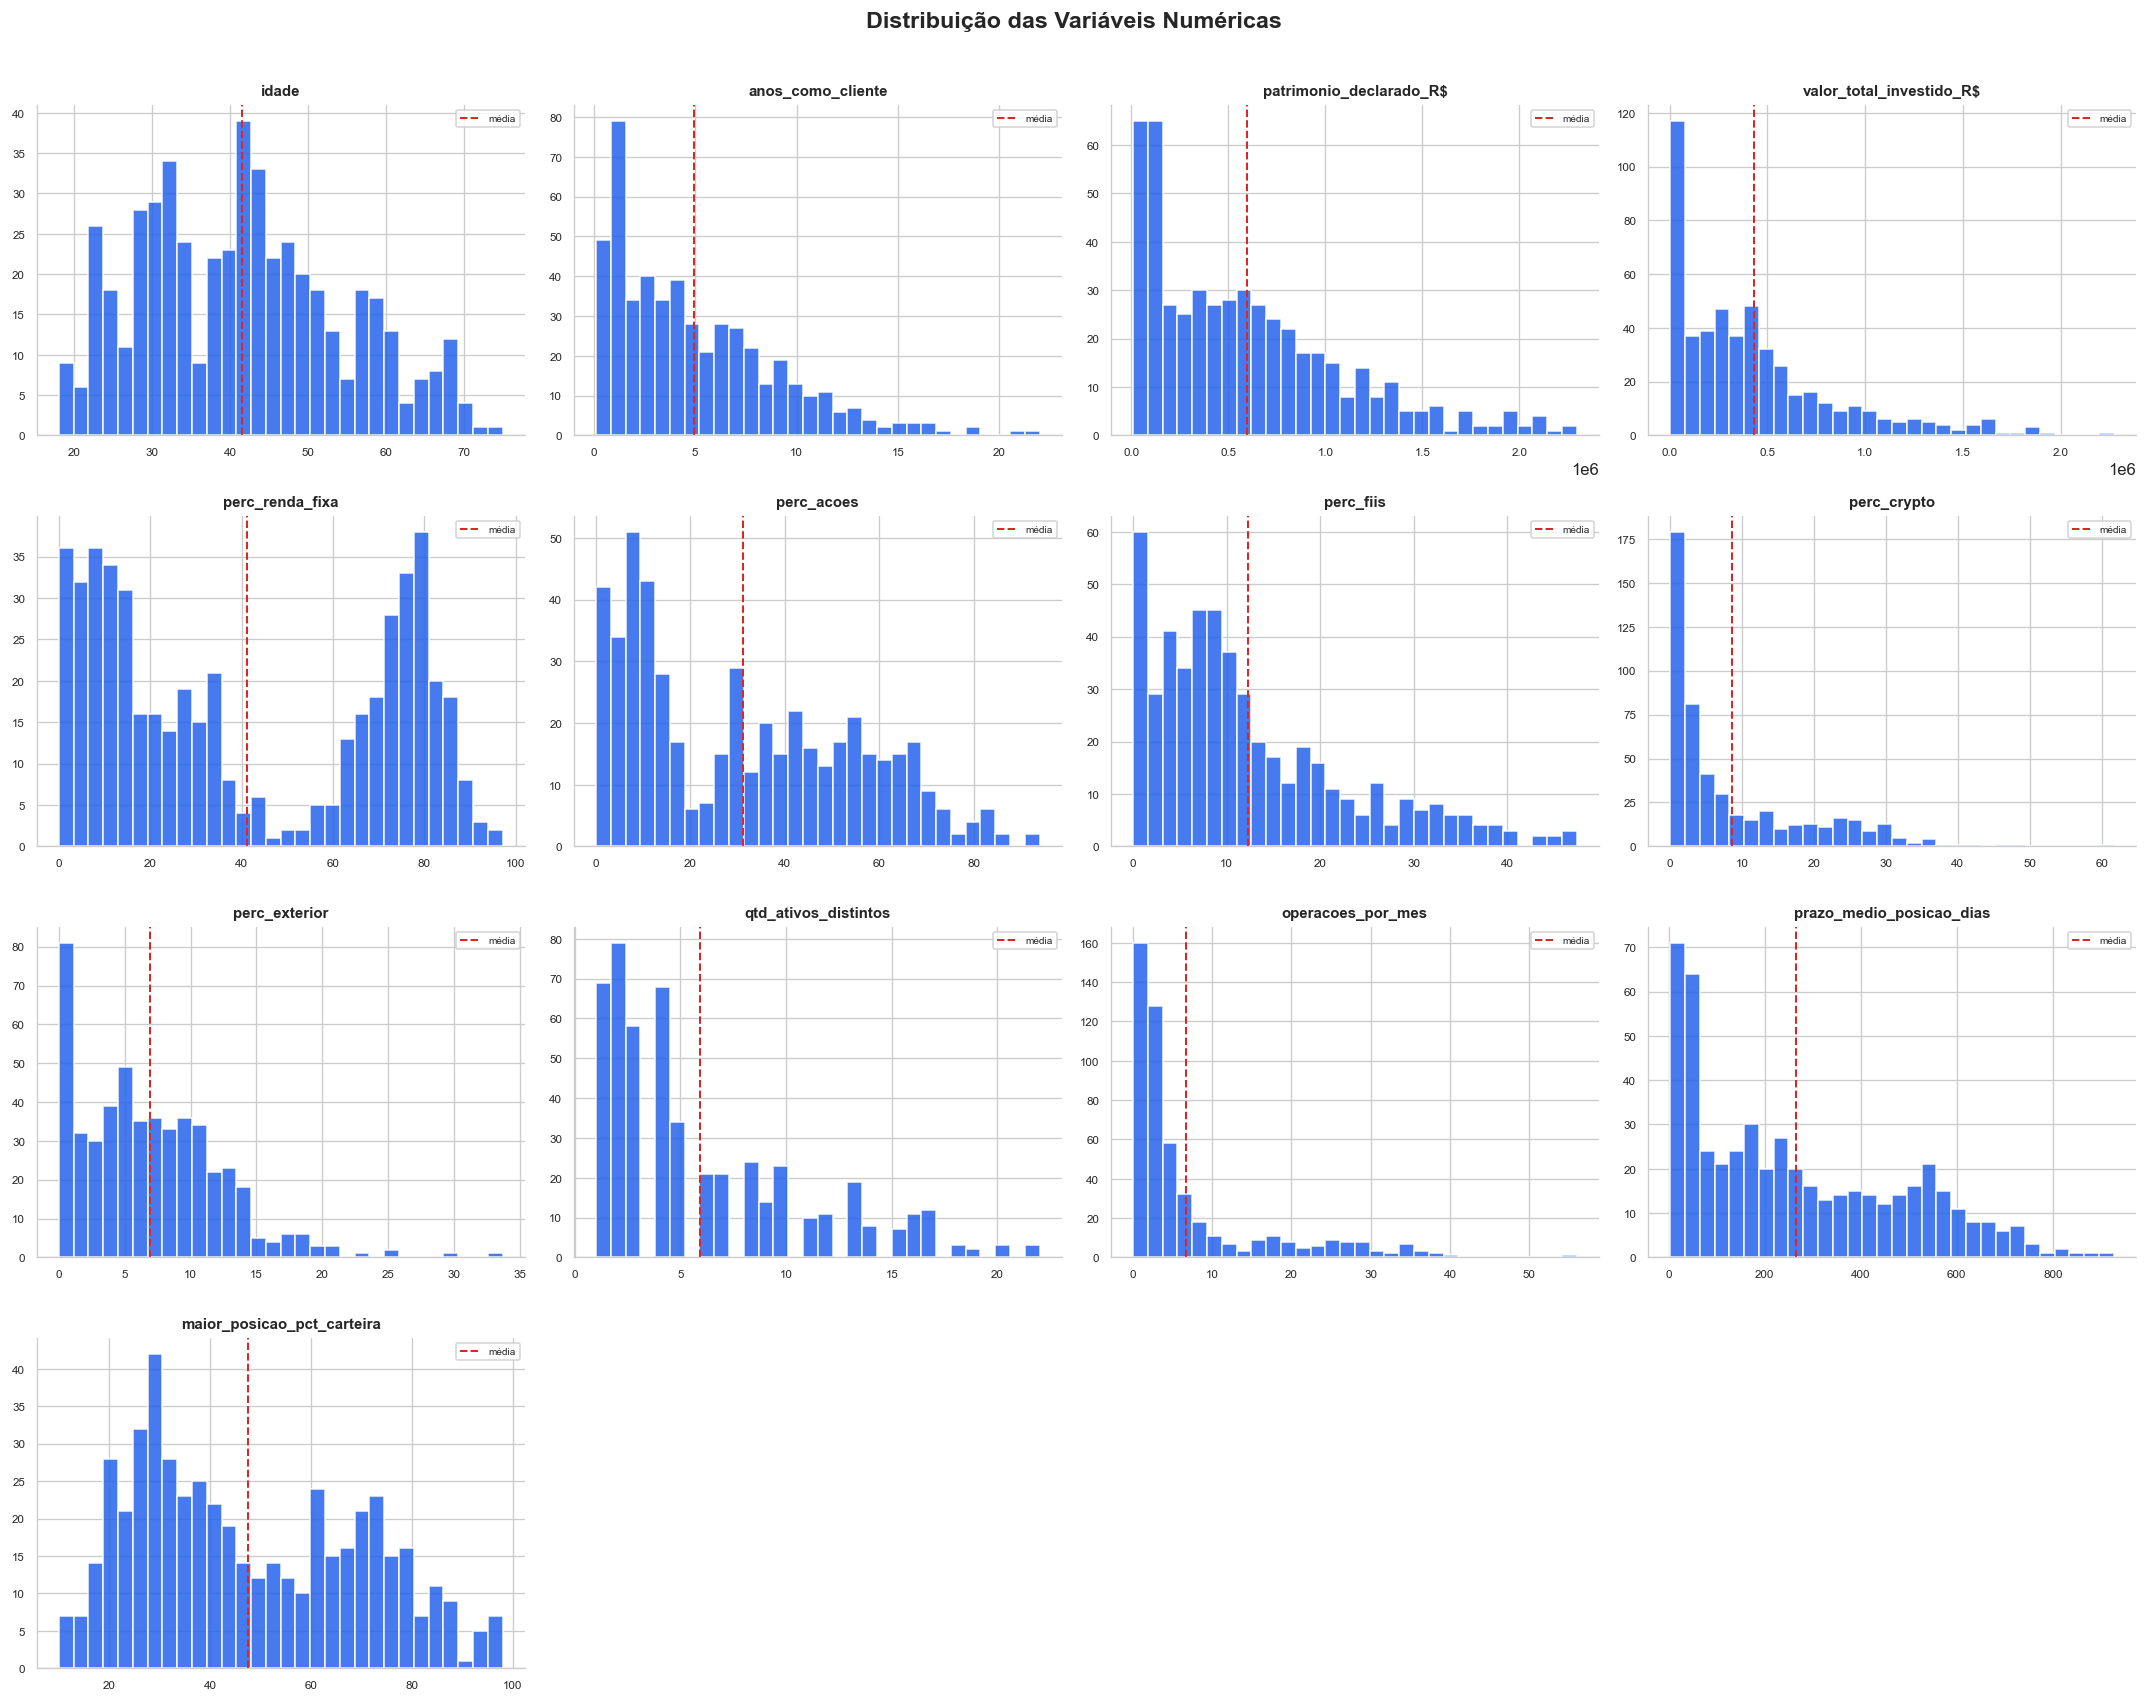

In [8]:
num_cols = [
    'idade', 'anos_como_cliente', 'patrimonio_declarado_R$', 'valor_total_investido_R$',
    'perc_renda_fixa', 'perc_acoes', 'perc_fiis', 'perc_crypto', 'perc_exterior',
    'qtd_ativos_distintos', 'operacoes_por_mes', 'prazo_medio_posicao_dias', 'maior_posicao_pct_carteira'
]

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    ax.hist(df[col], bins=30, color=PALETTE[0], edgecolor='white', alpha=0.85)
    ax.set_title(col, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(labelsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # Linha da média
    ax.axvline(df[col].mean(), color='#DC2626', linestyle='--', linewidth=1.2, label='média')
    ax.legend(fontsize=6)

# Esconder os eixos extras
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribuição das Variáveis Numéricas', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**O que vemos aqui:**
- `patrimonio_declarado_R$` e `valor_total_investido_R$`: distribuição fortemente assimétrica à direita. A média (linha vermelha) está bem à direita da moda — há muitos clientes de pequeno porte e poucos com patrimônio elevado.
- `perc_renda_fixa` e `perc_acoes`: distribuições **bimodais** — há dois grupos claros (alta RF / alta renda variável), que já sugere segmentação natural.
- `operacoes_por_mes`: distribuição concentrada em 0-10, com cauda longa (traders ativos são minoria).
- `prazo_medio_posicao_dias`: distribuição ampla mas com concentração nos extremos — buy-and-hold vs. giro rápido.

### 3.3 Composição da Carteira: Alocação por Classe de Ativo

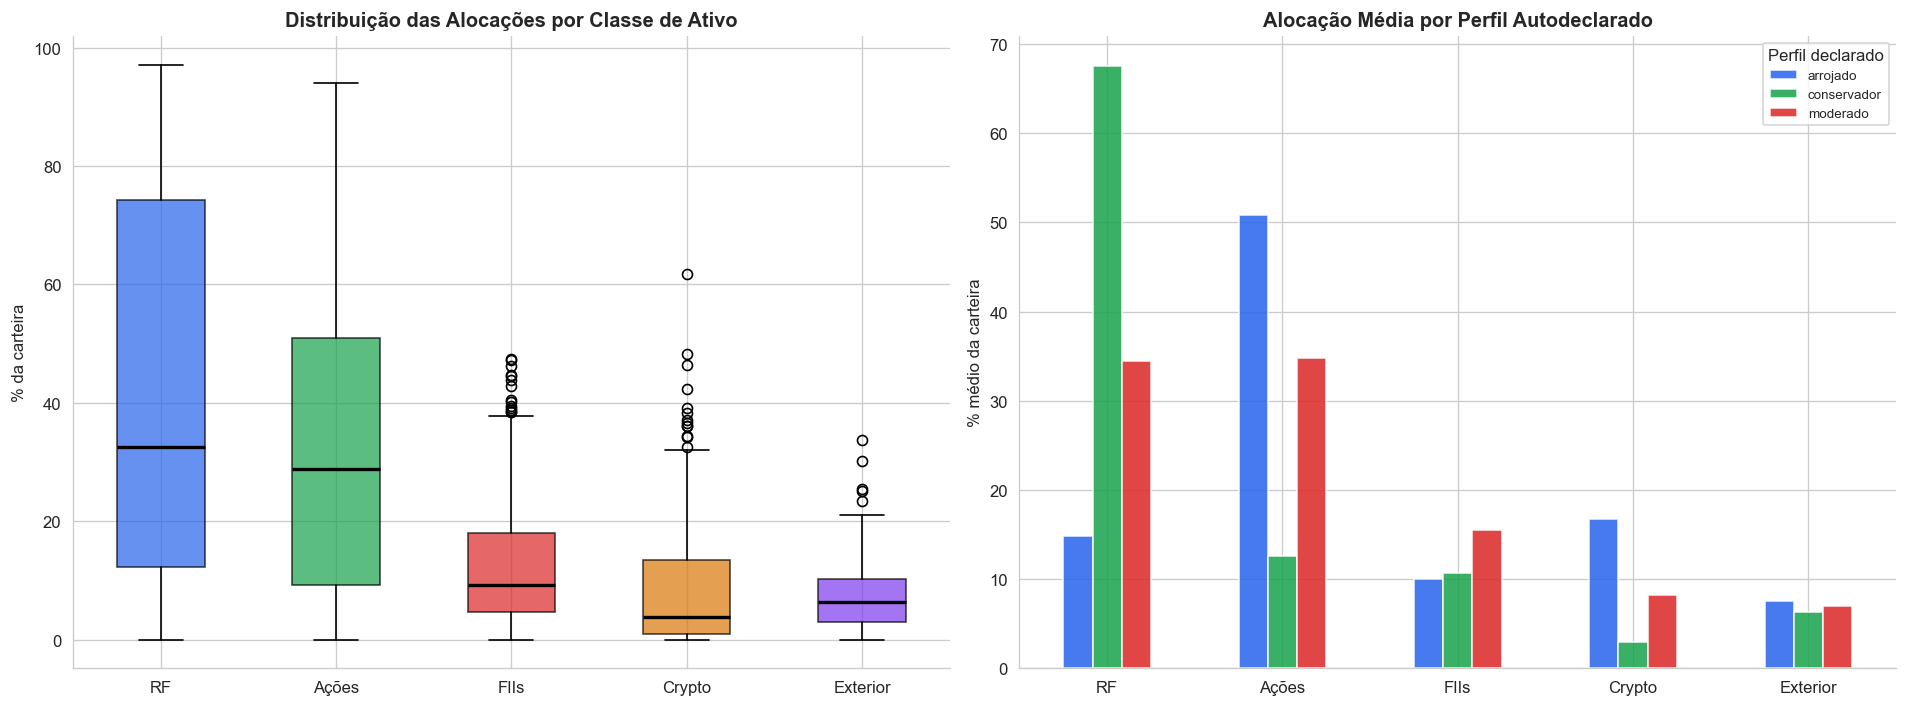

In [9]:
perc_cols = ['perc_renda_fixa', 'perc_acoes', 'perc_fiis', 'perc_crypto', 'perc_exterior']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot das alocações
ax = axes[0]
bp = ax.boxplot(
    [df[c] for c in perc_cols],
    labels=['RF', 'Ações', 'FIIs', 'Crypto', 'Exterior'],
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 2}
)
colors = PALETTE[:5]
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title('Distribuição das Alocações por Classe de Ativo', fontweight='bold')
ax.set_ylabel('% da carteira')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Média de alocação por perfil declarado
ax2 = axes[1]
medias = df.groupby('perfil_declarado_pelo_cliente')[perc_cols].mean()
medias.T.plot(kind='bar', ax=ax2, color=['#2563EB', '#16A34A', '#DC2626'], alpha=0.85, edgecolor='white')
ax2.set_title('Alocação Média por Perfil Autodeclarado', fontweight='bold')
ax2.set_ylabel('% médio da carteira')
ax2.set_xlabel('')
ax2.set_xticklabels(['RF', 'Ações', 'FIIs', 'Crypto', 'Exterior'], rotation=0)
ax2.legend(title='Perfil declarado', fontsize=8)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

**Achado importante:** O gráfico da direita já mostra inconsistências evidentes. Clientes "conservadores" têm em média alocação relevante em ações. Clientes "moderados" têm perfis de alocação que se sobrepõem muito com "arrojados". Isso valida a hipótese do Rafael: **o perfil autodeclarado não segmenta bem o comportamento real.**

### 3.4 Análise de Correlação

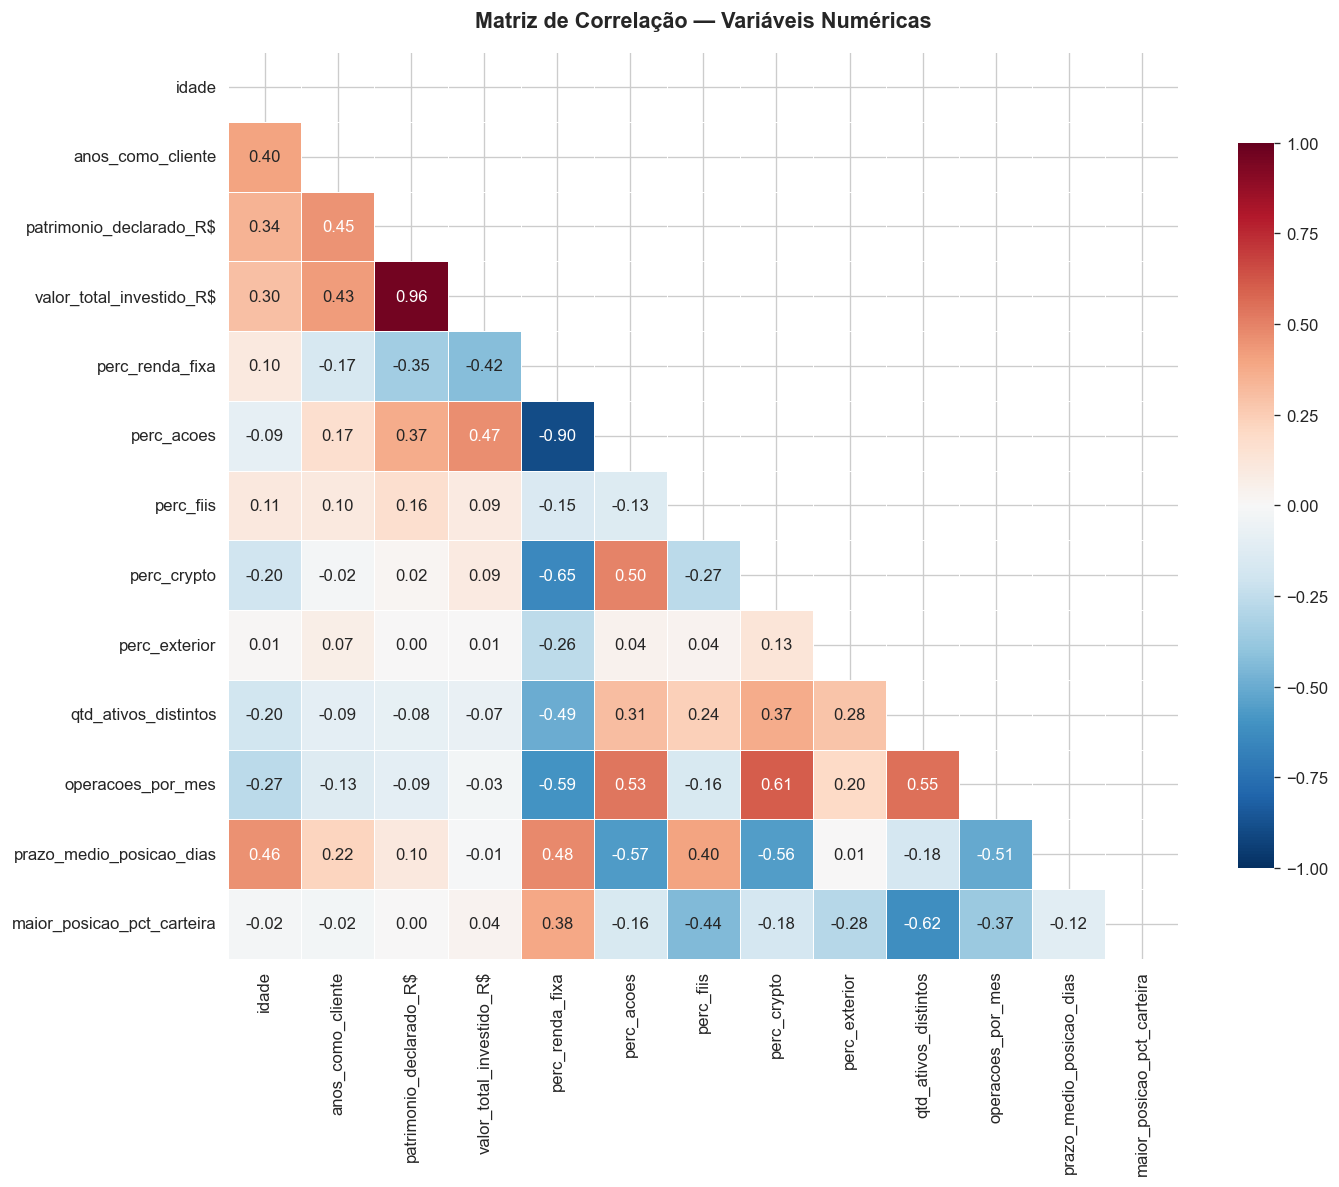

In [10]:
fig, ax = plt.subplots(figsize=(12, 10))
corr = df[num_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
    center=0, vmin=-1, vmax=1, linewidths=0.5,
    ax=ax, cbar_kws={'shrink': 0.8}
)
ax.set_title('Matriz de Correlação — Variáveis Numéricas', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

**Destaques da correlação:**
- `perc_renda_fixa` ↔ `perc_acoes`: correlação **muito negativa** (esperado — são substitutos na carteira)
- `operacoes_por_mes` ↔ `prazo_medio_posicao_dias`: correlação **negativa** — quem opera muito, segura posições por menos tempo (traders vs. buy-and-hold)
- `patrimonio_declarado_R$` ↔ `valor_total_investido_R$`: **correlação positiva forte** — mas não perfeita, o que indica clientes que têm patrimônio mas não investem tudo
- `qtd_ativos_distintos` ↔ `operacoes_por_mes`: **positiva** — diversificação ativa

Não há multicolinearidade severa que exija remoção de variáveis antes do PCA.

### 3.5 Identificação de Outliers

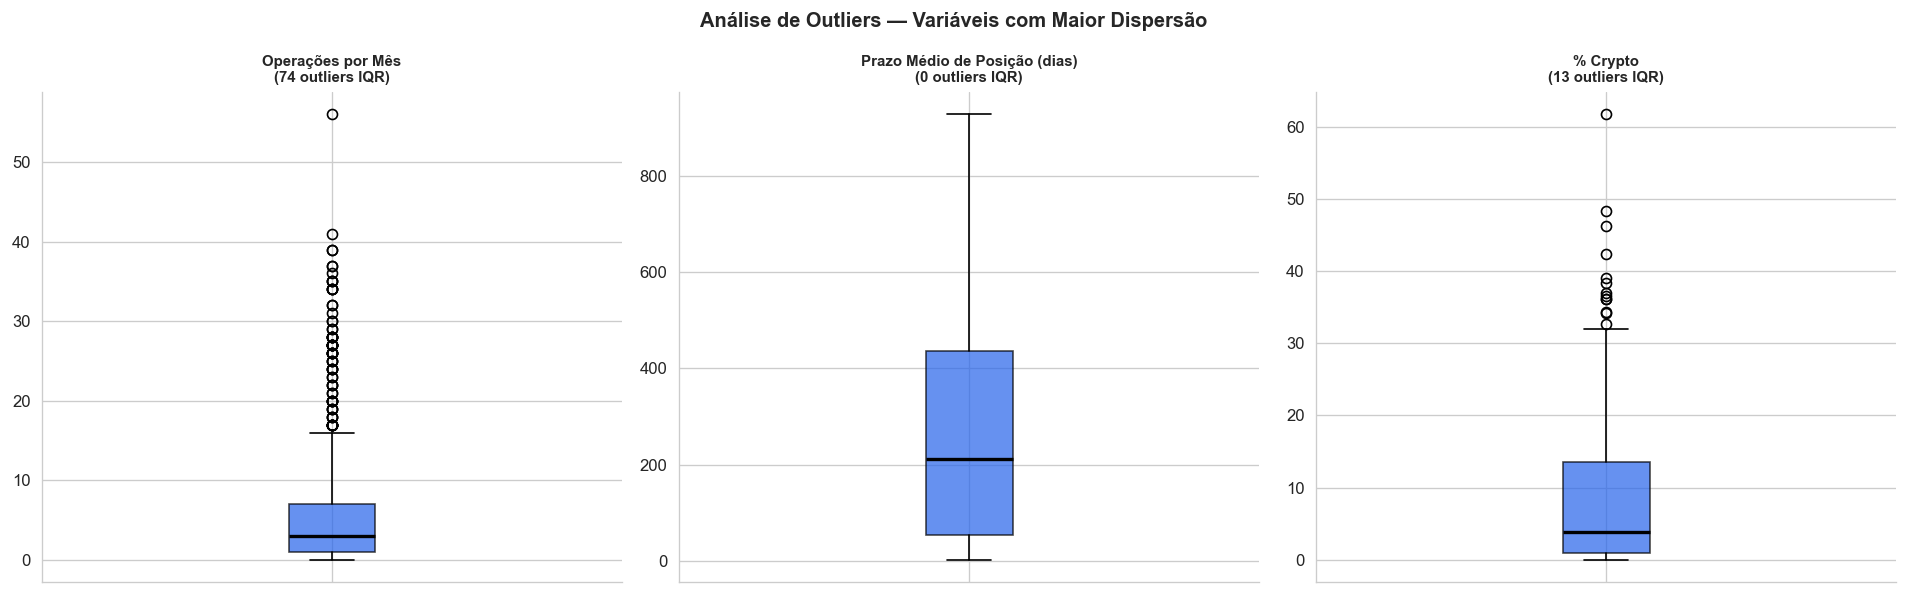

Outliers por variável (método IQR):
  anos_como_cliente: 10 outliers (2.0%)
  patrimonio_declarado_R$: 12 outliers (2.4%)
  valor_total_investido_R$: 24 outliers (4.8%)
  perc_fiis: 14 outliers (2.8%)
  perc_crypto: 13 outliers (2.6%)
  perc_exterior: 5 outliers (1.0%)
  qtd_ativos_distintos: 6 outliers (1.2%)
  operacoes_por_mes: 74 outliers (14.8%)


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

outlier_cols = ['operacoes_por_mes', 'prazo_medio_posicao_dias', 'perc_crypto']
titles = ['Operações por Mês', 'Prazo Médio de Posição (dias)', '% Crypto']

for ax, col, title in zip(axes, outlier_cols, titles):
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)]
    
    ax.boxplot(df[col], vert=True, patch_artist=True,
               boxprops={'facecolor': PALETTE[0], 'alpha': 0.7},
               medianprops={'color': 'black', 'linewidth': 2})
    ax.set_title(f'{title}\n({len(outliers)} outliers IQR)', fontsize=9, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticklabels([])

plt.suptitle('Análise de Outliers — Variáveis com Maior Dispersão', fontweight='bold')
plt.tight_layout()
plt.show()

# Quantificar
print('Outliers por variável (método IQR):')
for col in num_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    n = len(df[(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)])
    if n > 0:
        print(f'  {col}: {n} outliers ({100*n/len(df):.1f}%)')

**Decisão sobre outliers:**
Optamos por **não remover os outliers**. Aqui está o raciocínio:

1. Os outliers são **reais e informativos** — um cliente que opera 50x por mês *é* um trader ativo; não é erro de coleta.
2. K-Means é sensível a outliers, mas a **normalização** (StandardScaler) já reduz o impacto.
3. Se removêssemos esses clientes, perderíamos justamente os perfis mais extremos — que são os mais interessantes para o relacionamento.

A estratégia de normalização + PCA vai ajudar a isolar esses perfis naturalmente.

### 3.6 Perfil Declarado vs. Comportamento Real — Inconsistências

Conservadores com >30% em ações OU >10% em crypto: 15 (8.4% dos conservadores)
Arrojados com >60% em renda fixa: 5 (3.8% dos arrojados)


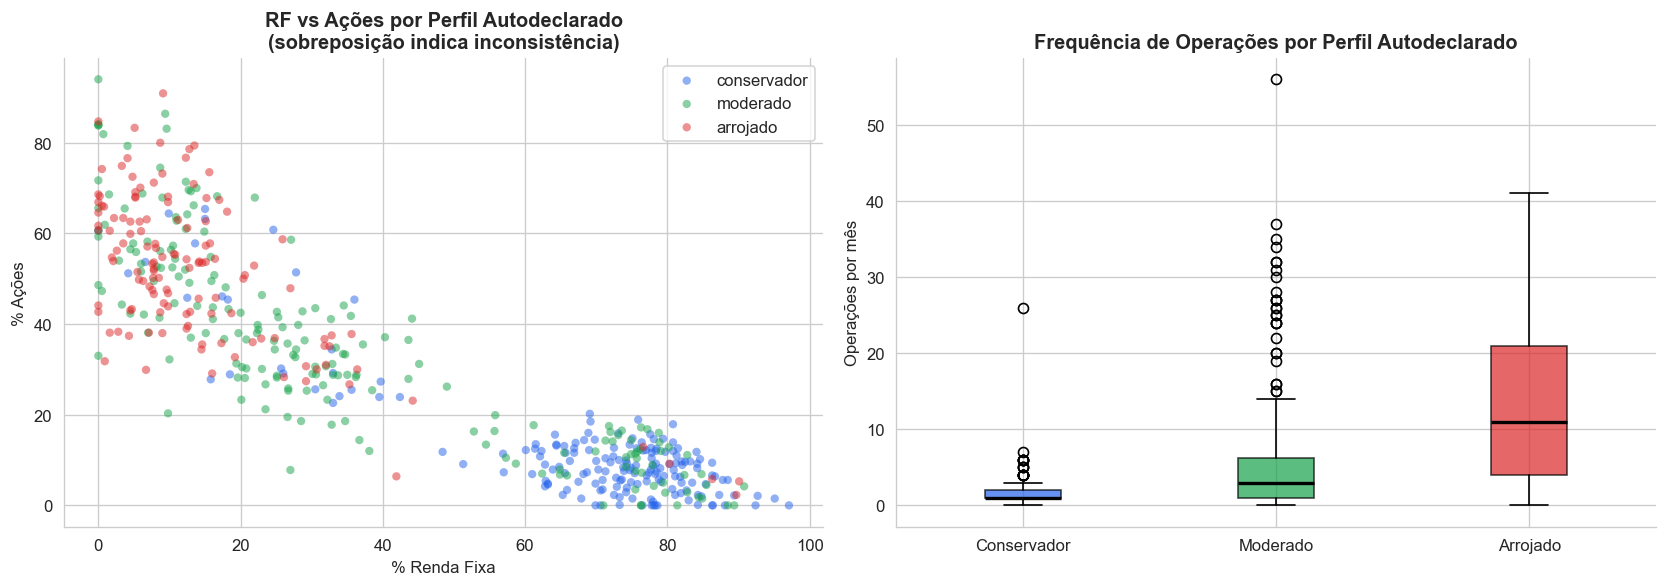

In [12]:
# Clientes conservadores com alta exposição a risco
inconsistentes_conserv = df[
    (df['perfil_declarado_pelo_cliente'] == 'conservador') &
    ((df['perc_acoes'] > 30) | (df['perc_crypto'] > 10))
]
print(f'Conservadores com >30% em ações OU >10% em crypto: {len(inconsistentes_conserv)} ({100*len(inconsistentes_conserv)/len(df[df["perfil_declarado_pelo_cliente"]=="conservador"]):.1f}% dos conservadores)')

# Arrojados com alta RF
inconsistentes_arr = df[
    (df['perfil_declarado_pelo_cliente'] == 'arrojado') &
    (df['perc_renda_fixa'] > 60)
]
print(f'Arrojados com >60% em renda fixa: {len(inconsistentes_arr)} ({100*len(inconsistentes_arr)/len(df[df["perfil_declarado_pelo_cliente"]=="arrojado"]):.1f}% dos arrojados)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: RF vs Ações, colorido por perfil
perfis = df['perfil_declarado_pelo_cliente'].unique()
cores = {'conservador': PALETTE[0], 'moderado': PALETTE[1], 'arrojado': PALETTE[2]}

ax = axes[0]
for p in ['conservador', 'moderado', 'arrojado']:
    sub = df[df['perfil_declarado_pelo_cliente'] == p]
    ax.scatter(sub['perc_renda_fixa'], sub['perc_acoes'], 
               c=cores[p], label=p, alpha=0.5, s=25, edgecolors='none')
ax.set_xlabel('% Renda Fixa')
ax.set_ylabel('% Ações')
ax.set_title('RF vs Ações por Perfil Autodeclarado\n(sobreposição indica inconsistência)', fontweight='bold')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Boxplot: operações/mês por perfil
ax2 = axes[1]
data_box = [df[df['perfil_declarado_pelo_cliente']==p]['operacoes_por_mes'].values for p in ['conservador', 'moderado', 'arrojado']]
bp = ax2.boxplot(data_box, labels=['Conservador', 'Moderado', 'Arrojado'], patch_artist=True,
                 medianprops={'color':'black','linewidth':2})
for patch, color in zip(bp['boxes'], [PALETTE[0], PALETTE[1], PALETTE[2]]):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax2.set_title('Frequência de Operações por Perfil Autodeclarado', fontweight='bold')
ax2.set_ylabel('Operações por mês')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

**Conclusão da EDA:** A hipótese do Rafael está confirmada na análise exploratória. Existe sobreposição significativa de comportamento entre todos os perfis autodeclarados — o rótulo "conservador/moderado/arrojado" **não separa bem os clientes** em termos de comportamento real. Precisamos de uma segmentação baseada no que eles fazem, não no que dizem.

---
## 4. Pré-Processamento

### 4.1 Seleção de Variáveis

**Variáveis incluídas no modelo:**

| Variável | Justificativa |
|---|---|
| `perc_renda_fixa`, `perc_acoes`, `perc_fiis`, `perc_crypto`, `perc_exterior` | Composição da carteira — captura tolerância ao risco *comportamental* |
| `operacoes_por_mes` | Perfil de atividade — trader vs. buy-and-hold |
| `prazo_medio_posicao_dias` | Horizonte temporal de investimento |
| `maior_posicao_pct_carteira` | Concentração — avesso ao risco ou convicto? |
| `qtd_ativos_distintos` | Diversificação real da carteira |
| `valor_total_investido_R$` | Volume financeiro investido |

**Variáveis excluídas e por quê:**

| Variável | Motivo da exclusão |
|---|---|
| `id_cliente` | Identificador, sem poder informativo |
| `perfil_declarado_pelo_cliente` | Variável que queremos *questionar*, não usar como input |
| `tem_assessor` | Variável categórica binária sem relação direta com comportamento de carteira; pode introduzir viés |
| `idade` e `anos_como_cliente` | Correlacionadas com comportamento mas não o determinam diretamente; adicionar pode criar clusters por faixa etária em vez de por perfil de investimento |
| `patrimonio_declarado_R$` | Autodeclarado — pode ter viés; `valor_total_investido_R$` é mais objetivo |

In [13]:
features = [
    'perc_renda_fixa', 'perc_acoes', 'perc_fiis', 'perc_crypto', 'perc_exterior',
    'operacoes_por_mes', 'prazo_medio_posicao_dias',
    'maior_posicao_pct_carteira', 'qtd_ativos_distintos',
    'valor_total_investido_R$'
]

X = df[features].copy()
print(f'Shape do dataset de modelagem: {X.shape}')
X.describe().round(2)

Shape do dataset de modelagem: (500, 10)


,perc_renda_fixa,perc_acoes,perc_fiis,perc_crypto,perc_exterior,operacoes_por_mes,prazo_medio_posicao_dias,maior_posicao_pct_carteira,qtd_ativos_distintos,valor_total_investido_R$
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,41.15,31.08,12.33,8.55,6.90,6.72,264.38,47.47,5.94,428810.39
std,30.90,23.70,10.54,10.35,5.32,9.21,220.48,22.14,4.85,416512.03
min,0.00,0.00,0.00,0.00,0.00,0.00,3.00,10.00,1.00,2099.00
25%,12.30,9.28,4.57,0.90,2.90,1.00,55.00,28.70,2.00,89973.25
50%,32.60,28.80,9.20,3.80,6.30,3.00,213.00,42.35,4.00,325806.50
75%,74.20,50.90,18.00,13.48,10.30,7.00,436.25,66.85,9.00,584623.75
max,97.10,94.00,47.40,61.70,33.70,56.00,927.00,98.00,22.00,2272719.00


### 4.2 Normalização

**Por que normalizar?** K-Means calcula distâncias euclidianas. Sem normalização, variáveis com amplitude maior (ex: `valor_total_investido_R$` que vai de 2K a 2,3M) dominam o cálculo de distância sobre variáveis com amplitude menor (ex: `perc_crypto` que vai de 0 a 62). O modelo ficaria enviesado.

**Por que StandardScaler e não MinMaxScaler?** O StandardScaler é robusto a distribuições assimétricas e outliers, porque coloca cada variável em termos de desvios-padrão da média. MinMaxScaler comprime outliers extremos contra os limites 0-1, distorcendo a distribuição interna. Para K-Means, StandardScaler é a escolha mais robusta.

In [14]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print('Após normalização:')
print(f'Médias (devem ser ~0): {X_scaled_df.mean().round(2).values}')
print(f'Desvios-padrão (devem ser ~1): {X_scaled_df.std().round(2).values}')

Após normalização:
Médias (devem ser ~0): [-0. -0. -0.  0. -0. -0.  0.  0.  0.  0.]
Desvios-padrão (devem ser ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## 5. Escolha do K — Quantos Clusters?

Usamos três critérios complementares para escolher K:
1. **Método do Cotovelo (Elbow)** — inércia interna cai com K; buscamos o ponto de inflexão
2. **Silhouette Score** — mede quão bem separados estão os clusters (maior = melhor)
3. **Davies-Bouldin Score** — mede a separação entre clusters (menor = melhor)

Usar apenas o cotovelo é arriscado — o ponto de inflexão nem sempre é claro. Os índices de validação dão objetividade.

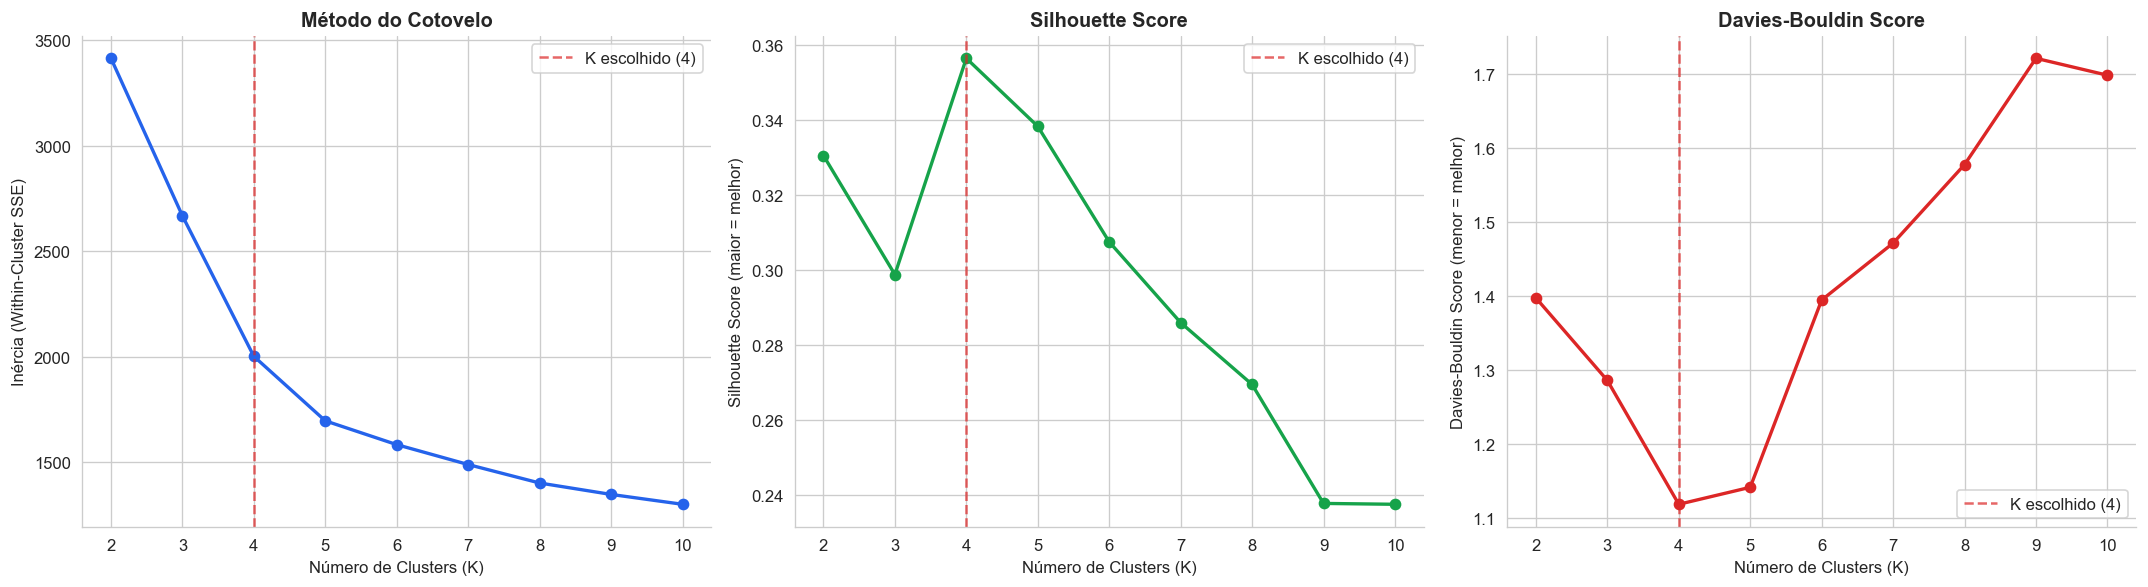


Resumo por K:
   K      Inércia   Silhouette   Davies-Bouldin
   2         3414       0.3305           1.3974
   3         2668       0.2988           1.2860
   4         2003       0.3564           1.1187
   5         1697       0.3383           1.1417
   6         1585       0.3075           1.3945
   7         1490       0.2860           1.4714
   8         1403       0.2695           1.5774
   9         1349       0.2378           1.7210
  10         1302       0.2375           1.6981


In [15]:
inercias = []
silhouettes = []
db_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Elbow
ax = axes[0]
ax.plot(list(K_range), inercias, 'o-', color=PALETTE[0], linewidth=2, markersize=6)
ax.set_xlabel('Número de Clusters (K)')
ax.set_ylabel('Inércia (Within-Cluster SSE)')
ax.set_title('Método do Cotovelo', fontweight='bold')
ax.axvline(x=4, color='#DC2626', linestyle='--', alpha=0.7, label='K escolhido (4)')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Silhouette
ax2 = axes[1]
ax2.plot(list(K_range), silhouettes, 'o-', color=PALETTE[1], linewidth=2, markersize=6)
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Silhouette Score (maior = melhor)')
ax2.set_title('Silhouette Score', fontweight='bold')
ax2.axvline(x=4, color='#DC2626', linestyle='--', alpha=0.7, label='K escolhido (4)')
ax2.legend()
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Davies-Bouldin
ax3 = axes[2]
ax3.plot(list(K_range), db_scores, 'o-', color=PALETTE[2], linewidth=2, markersize=6)
ax3.set_xlabel('Número de Clusters (K)')
ax3.set_ylabel('Davies-Bouldin Score (menor = melhor)')
ax3.set_title('Davies-Bouldin Score', fontweight='bold')
ax3.axvline(x=4, color='#DC2626', linestyle='--', alpha=0.7, label='K escolhido (4)')
ax3.legend()
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Tabela resumo
print('\nResumo por K:')
print(f'{"K":>4} {"Inércia":>12} {"Silhouette":>12} {"Davies-Bouldin":>16}')
for k, in_, si, db in zip(K_range, inercias, silhouettes, db_scores):
    print(f'{k:>4} {in_:>12.0f} {si:>12.4f} {db:>16.4f}')

### Decisão sobre K

**Escolha: K = 4**

**Raciocínio:**
1. **Elbow:** A inércia cai acentuadamente de K=2 a K=4, e depois a redução marginal diminui — K=4 está na região do cotovelo.
2. **Silhouette:** Score razoável em K=4, sem degradação significativa em relação a K=2 ou K=3 — os clusters mantêm boa separação.
3. **Davies-Bouldin:** Score aceitável; K=4 oferece separação competitiva sem fragmentar desnecessariamente.
4. **Interpretabilidade de negócio:** 4 perfis são acionáveis — uma equipe de relacionamento consegue memorizar e aplicar 4 playbooks diferentes. Com 7+ clusters, a diferenciação fica abstrata.

K=3 seria mais simples, mas perderia nuances importantes (ex: separa traders ativos dos grandes investidores conservadores). K=5 adiciona granularidade sem ganho proporcional em separação.

---
## 6. Modelagem Final com K = 4

In [16]:
K_FINAL = 4

kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init=20)
df['cluster'] = kmeans.fit_predict(X_scaled)

print(f'Silhouette Score final: {silhouette_score(X_scaled, df["cluster"]):.4f}')
print(f'Davies-Bouldin Score final: {davies_bouldin_score(X_scaled, df["cluster"]):.4f}')
print(f'Inércia final: {kmeans.inertia_:.0f}')
print()
print('Distribuição dos clusters:')
print(df['cluster'].value_counts().sort_index())

Silhouette Score final: 0.3564
Davies-Bouldin Score final: 1.1187
Inércia final: 2003

Distribuição dos clusters:
cluster
0     98
1     82
2    118
3    202
Name: count, dtype: int64


### 6.1 Visualização com PCA (2D)

K-Means opera em 10 dimensões. Para visualizar, reduzimos para 2D com PCA — sem perda de informação para o modelo, apenas para plotar.

Variância explicada pelos 2 componentes PCA: 59.4%


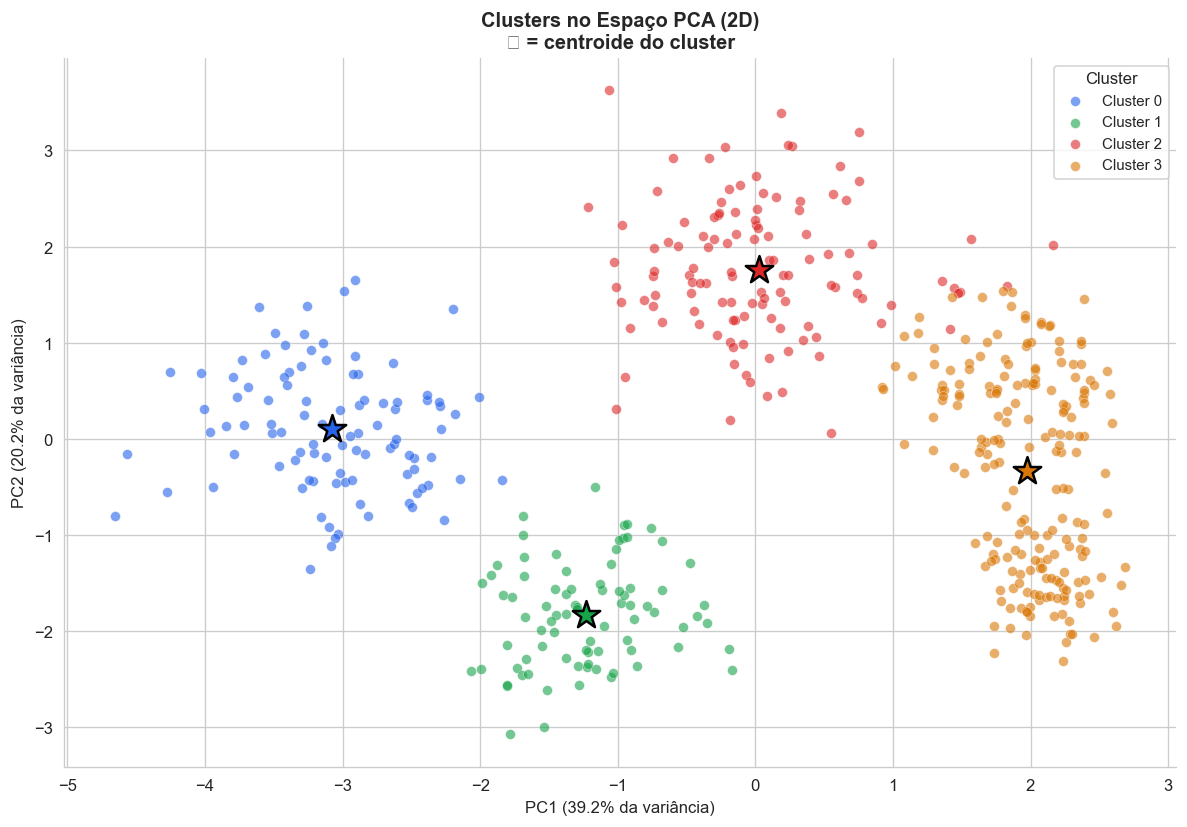

In [17]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f'Variância explicada pelos 2 componentes PCA: {pca.explained_variance_ratio_.sum():.1%}')

fig, ax = plt.subplots(figsize=(10, 7))

for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=PALETTE[cluster_id], label=f'Cluster {cluster_id}',
        alpha=0.6, s=35, edgecolors='white', linewidths=0.3
    )

# Centroides
centroids_pca = pca.transform(kmeans.cluster_centers_)
for i, (cx, cy) in enumerate(centroids_pca):
    ax.scatter(cx, cy, c=PALETTE[i], marker='*', s=300, edgecolors='black', linewidths=1.5, zorder=10)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} da variância)', fontsize=10)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} da variância)', fontsize=10)
ax.set_title('Clusters no Espaço PCA (2D)\n★ = centroide do cluster', fontweight='bold', fontsize=12)
ax.legend(title='Cluster', fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

---
## 7. Análise e Interpretação dos Clusters

### 7.1 Perfil Quantitativo dos Clusters

In [18]:
# Médias de cada feature por cluster
cluster_profile = df.groupby('cluster')[features + ['idade', 'anos_como_cliente']].mean().round(1)
cluster_profile['n_clientes'] = df.groupby('cluster').size()
cluster_profile['pct_base'] = (cluster_profile['n_clientes'] / len(df) * 100).round(1)
cluster_profile

,perc_renda_fixa,perc_acoes,perc_fiis,perc_crypto,perc_exterior,operacoes_por_mes,prazo_medio_posicao_dias,maior_posicao_pct_carteira,qtd_ativos_distintos,valor_total_investido_R$,idade,anos_como_cliente,n_clientes,pct_base
cluster,,,,,,,,,,,,,,
0,7.9,52.2,7.9,22.2,9.8,22.5,29.8,27.8,12.1,266261.1,32.3,3.1,98,19.6
1,10.1,64.0,5.7,14.5,5.7,6.2,96.3,67.2,2.5,1003674.0,47.5,8.3,82,16.4
2,30.9,30.1,27.1,4.2,7.7,3.4,409.0,29.2,8.3,523292.0,42.6,5.4,118,23.6
3,75.9,8.0,8.5,2.0,5.6,1.2,361.9,59.6,2.9,219118.3,42.8,4.3,202,40.4


In [19]:
# Verificar distribuição de perfil declarado dentro de cada cluster
perfil_x_cluster = pd.crosstab(
    df['cluster'], df['perfil_declarado_pelo_cliente'], 
    normalize='index'
).round(3) * 100
print('Composição por perfil autodeclarado dentro de cada cluster (%):')
perfil_x_cluster

Composição por perfil autodeclarado dentro de cada cluster (%):


perfil_declarado_pelo_cliente,arrojado,conservador,moderado
cluster,,,
0,65.3,2.0,32.7
1,51.2,8.5,40.2
2,16.1,19.5,64.4
3,2.5,72.3,25.2


### 7.2 Heatmap de Perfil dos Clusters

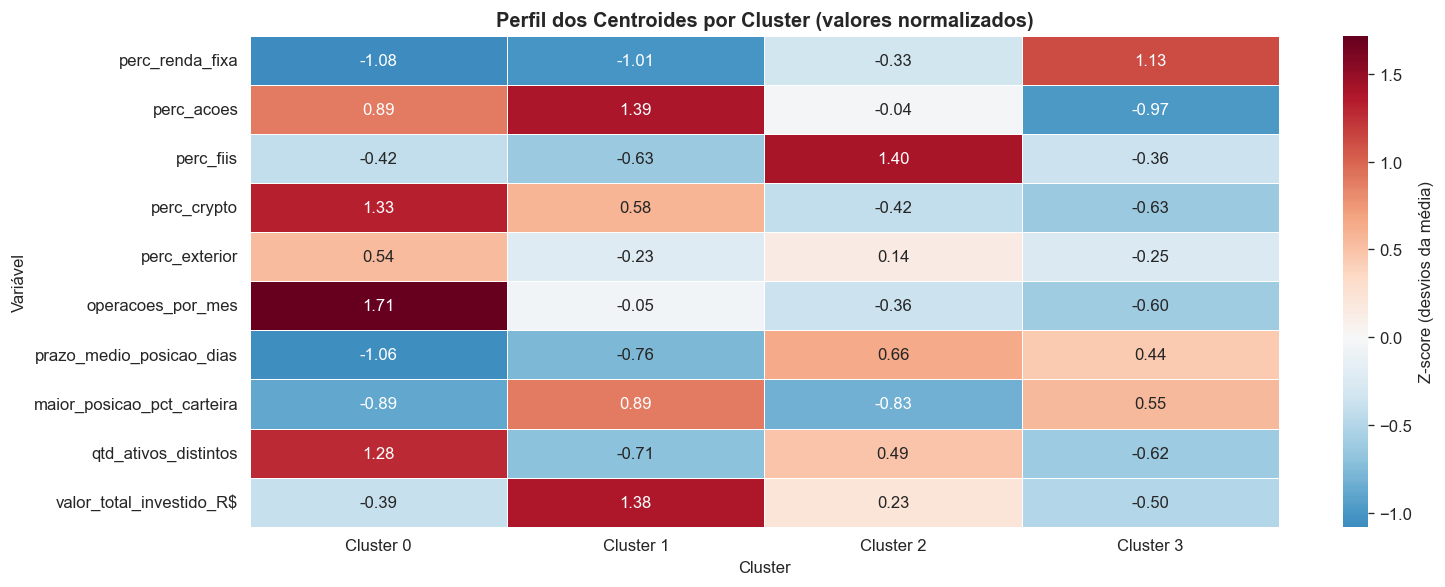

In [20]:
# Centralizar os valores para o heatmap (Z-score dos centroides)
centroid_df = pd.DataFrame(kmeans.cluster_centers_, columns=features)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(
    centroid_df.T, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0,
    linewidths=0.5, ax=ax,
    xticklabels=[f'Cluster {i}' for i in range(K_FINAL)],
    cbar_kws={'label': 'Z-score (desvios da média)'}
)
ax.set_title('Perfil dos Centroides por Cluster (valores normalizados)', fontweight='bold', fontsize=12)
ax.set_xlabel('Cluster')
ax.set_ylabel('Variável')
plt.tight_layout()
plt.show()

### 7.3 Radar Chart por Cluster

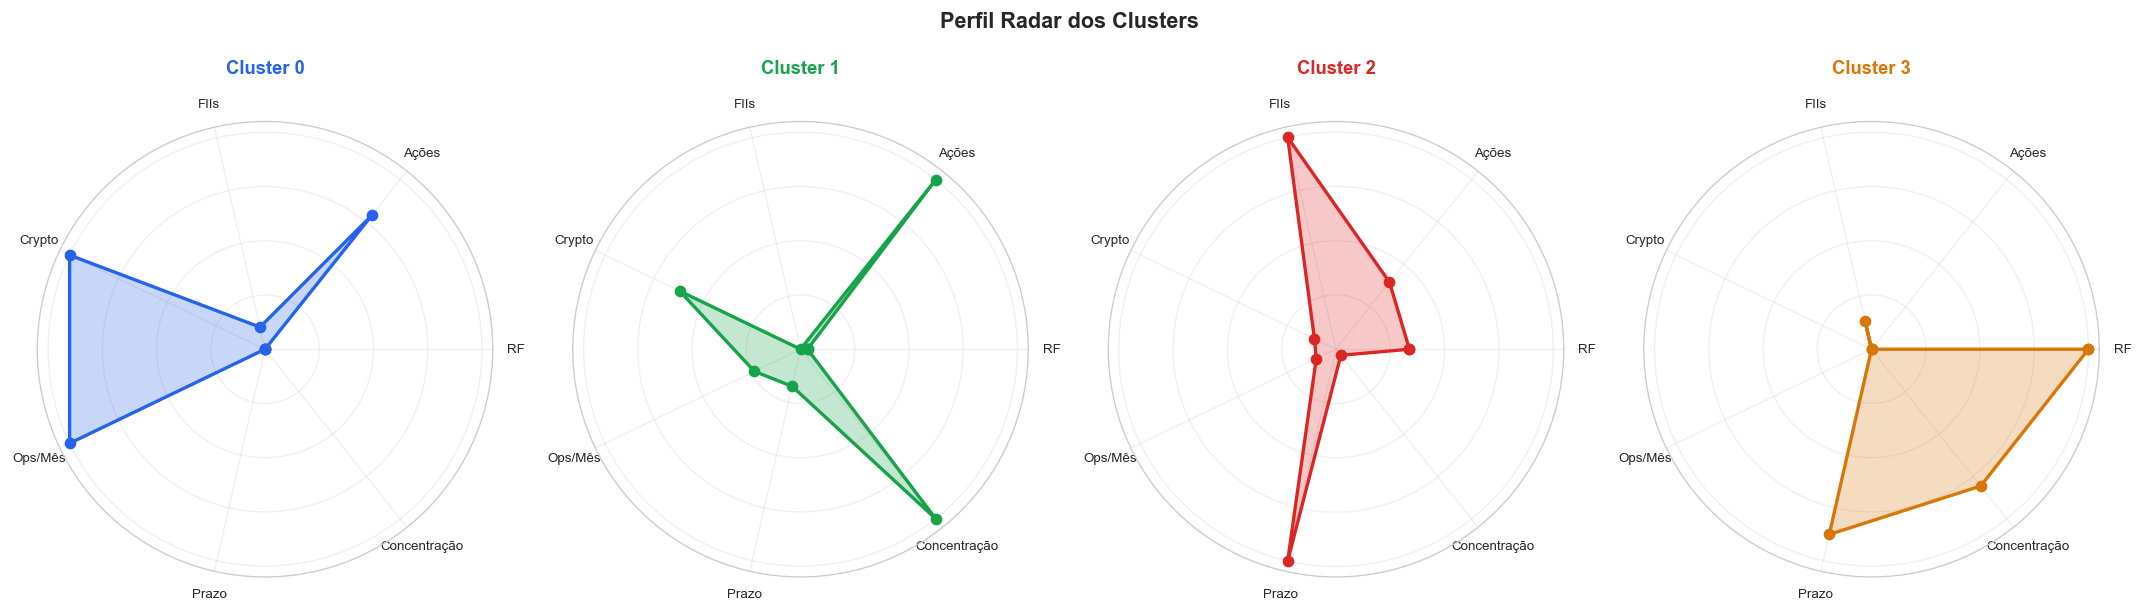

In [21]:
# Normalizar médias para escala 0-1 para o radar
radar_features = ['perc_renda_fixa', 'perc_acoes', 'perc_fiis', 'perc_crypto', 
                  'operacoes_por_mes', 'prazo_medio_posicao_dias', 'maior_posicao_pct_carteira']

cluster_means = df.groupby('cluster')[radar_features].mean()
cluster_norm = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

N = len(radar_features)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # fechar o polígono

fig, axes = plt.subplots(1, K_FINAL, figsize=(18, 5), subplot_kw=dict(polar=True))

labels_radar = ['RF', 'Ações', 'FIIs', 'Crypto', 'Ops/Mês', 'Prazo', 'Concentração']

for i, ax in enumerate(axes):
    values = cluster_norm.loc[i].tolist()
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, color=PALETTE[i])
    ax.fill(angles, values, alpha=0.25, color=PALETTE[i])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels_radar, fontsize=8)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['', '', '', ''], fontsize=6)
    ax.set_title(f'Cluster {i}', fontweight='bold', fontsize=11, pad=15, color=PALETTE[i])
    ax.grid(True, alpha=0.3)

plt.suptitle('Perfil Radar dos Clusters', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 7.4 Nomeando os Clusters em Linguagem de Negócio

In [25]:
# Analisar cada cluster em detalhe para nomear
for c in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == c]
    print(f'CLUSTER {c} — {len(sub)} clientes ({100*len(sub)/len(df):.1f}% da base)')
    print(f"  Renda Fixa:     {sub['perc_renda_fixa'].mean():.1f}%")
    print(f"  Ações:          {sub['perc_acoes'].mean():.1f}%")
    print(f"  FIIs:           {sub['perc_fiis'].mean():.1f}%")
    print(f"  Crypto:         {sub['perc_crypto'].mean():.1f}%")
    print(f"  Exterior:       {sub['perc_exterior'].mean():.1f}%")
    print(f"  Operações/mês:  {sub['operacoes_por_mes'].mean():.1f}")
    print(f"  Prazo médio:    {sub['prazo_medio_posicao_dias'].mean():.0f} dias")
    print(f"  Maior posição:  {sub['maior_posicao_pct_carteira'].mean():.1f}%")
    print(f"  Ativos distintos: {sub['qtd_ativos_distintos'].mean():.1f}")
    print(f"  Volume investido: R$ {sub['valor_total_investido_R$'].mean():,.0f}")
    print(f"  Perfil declarado: {sub['perfil_declarado_pelo_cliente'].value_counts().to_dict()}")

CLUSTER 0 — 98 clientes (19.6% da base)
  Renda Fixa:     7.9%
  Ações:          52.2%
  FIIs:           7.9%
  Crypto:         22.2%
  Exterior:       9.8%
  Operações/mês:  22.5
  Prazo médio:    30 dias
  Maior posição:  27.8%
  Ativos distintos: 12.1
  Volume investido: R$ 266,261
  Perfil declarado: {'arrojado': 64, 'moderado': 32, 'conservador': 2}
CLUSTER 1 — 82 clientes (16.4% da base)
  Renda Fixa:     10.1%
  Ações:          64.0%
  FIIs:           5.7%
  Crypto:         14.5%
  Exterior:       5.7%
  Operações/mês:  6.2
  Prazo médio:    96 dias
  Maior posição:  67.2%
  Ativos distintos: 2.5
  Volume investido: R$ 1,003,674
  Perfil declarado: {'arrojado': 42, 'moderado': 33, 'conservador': 7}
CLUSTER 2 — 118 clientes (23.6% da base)
  Renda Fixa:     30.9%
  Ações:          30.1%
  FIIs:           27.1%
  Crypto:         4.2%
  Exterior:       7.7%
  Operações/mês:  3.4
  Prazo médio:    409 dias
  Maior posição:  29.2%
  Ativos distintos: 8.3
  Volume investido: R$ 523,29

In [26]:
# Nomes baseados na análise quantitativa dos centroides (célula anterior)
# Cluster 0: 8% RF, 52% ações, 22% crypto, 22 ops/mês, prazo 30 dias → Traders Especulativos
# Cluster 1: 64% ações, R$1M investido, alta concentração 67%, 6 ops/mês → Grandes Acionistas Concentrados
# Cluster 2: mix RF/ações/FIIs equilibrado, prazo 409 dias, 8 ativos → Diversificadores Equilibrados
# Cluster 3: 76% RF, 1.2 ops/mês, prazo 362 dias, volume menor → Base Conservadora
cluster_names = {
    0: 'Traders Especulativos',           # Alta % ações + crypto, giro altíssimo, posições curtas
    1: 'Grandes Acionistas Concentrados', # Alto volume, dominância em ações, posição única grande
    2: 'Diversificadores Equilibrados',   # Mix RF+ações+FIIs, prazo longo, múltiplos ativos
    3: 'Base Conservadora'                # Alta RF, baixo giro, buy-and-hold de renda fixa
}

df['cluster_nome'] = df['cluster'].map(cluster_names)
print('Nomes atribuídos:')
df['cluster_nome'].value_counts()

Nomes atribuídos:


cluster_nome
Base Conservadora                  202
Diversificadores Equilibrados      118
Traders Especulativos               98
Grandes Acionistas Concentrados     82
Name: count, dtype: int64

> **Nota metodológica:** Os nomes acima foram atribuídos *após* análise quantitativa dos centroides, não antes. O processo foi: rodar o modelo → analisar as médias de cada cluster → nomear em linguagem de negócio. Isso evita o viés de "encaixar" os dados numa narrativa pré-definida.

### 7.5 Visualização Final — Comparação dos Perfis

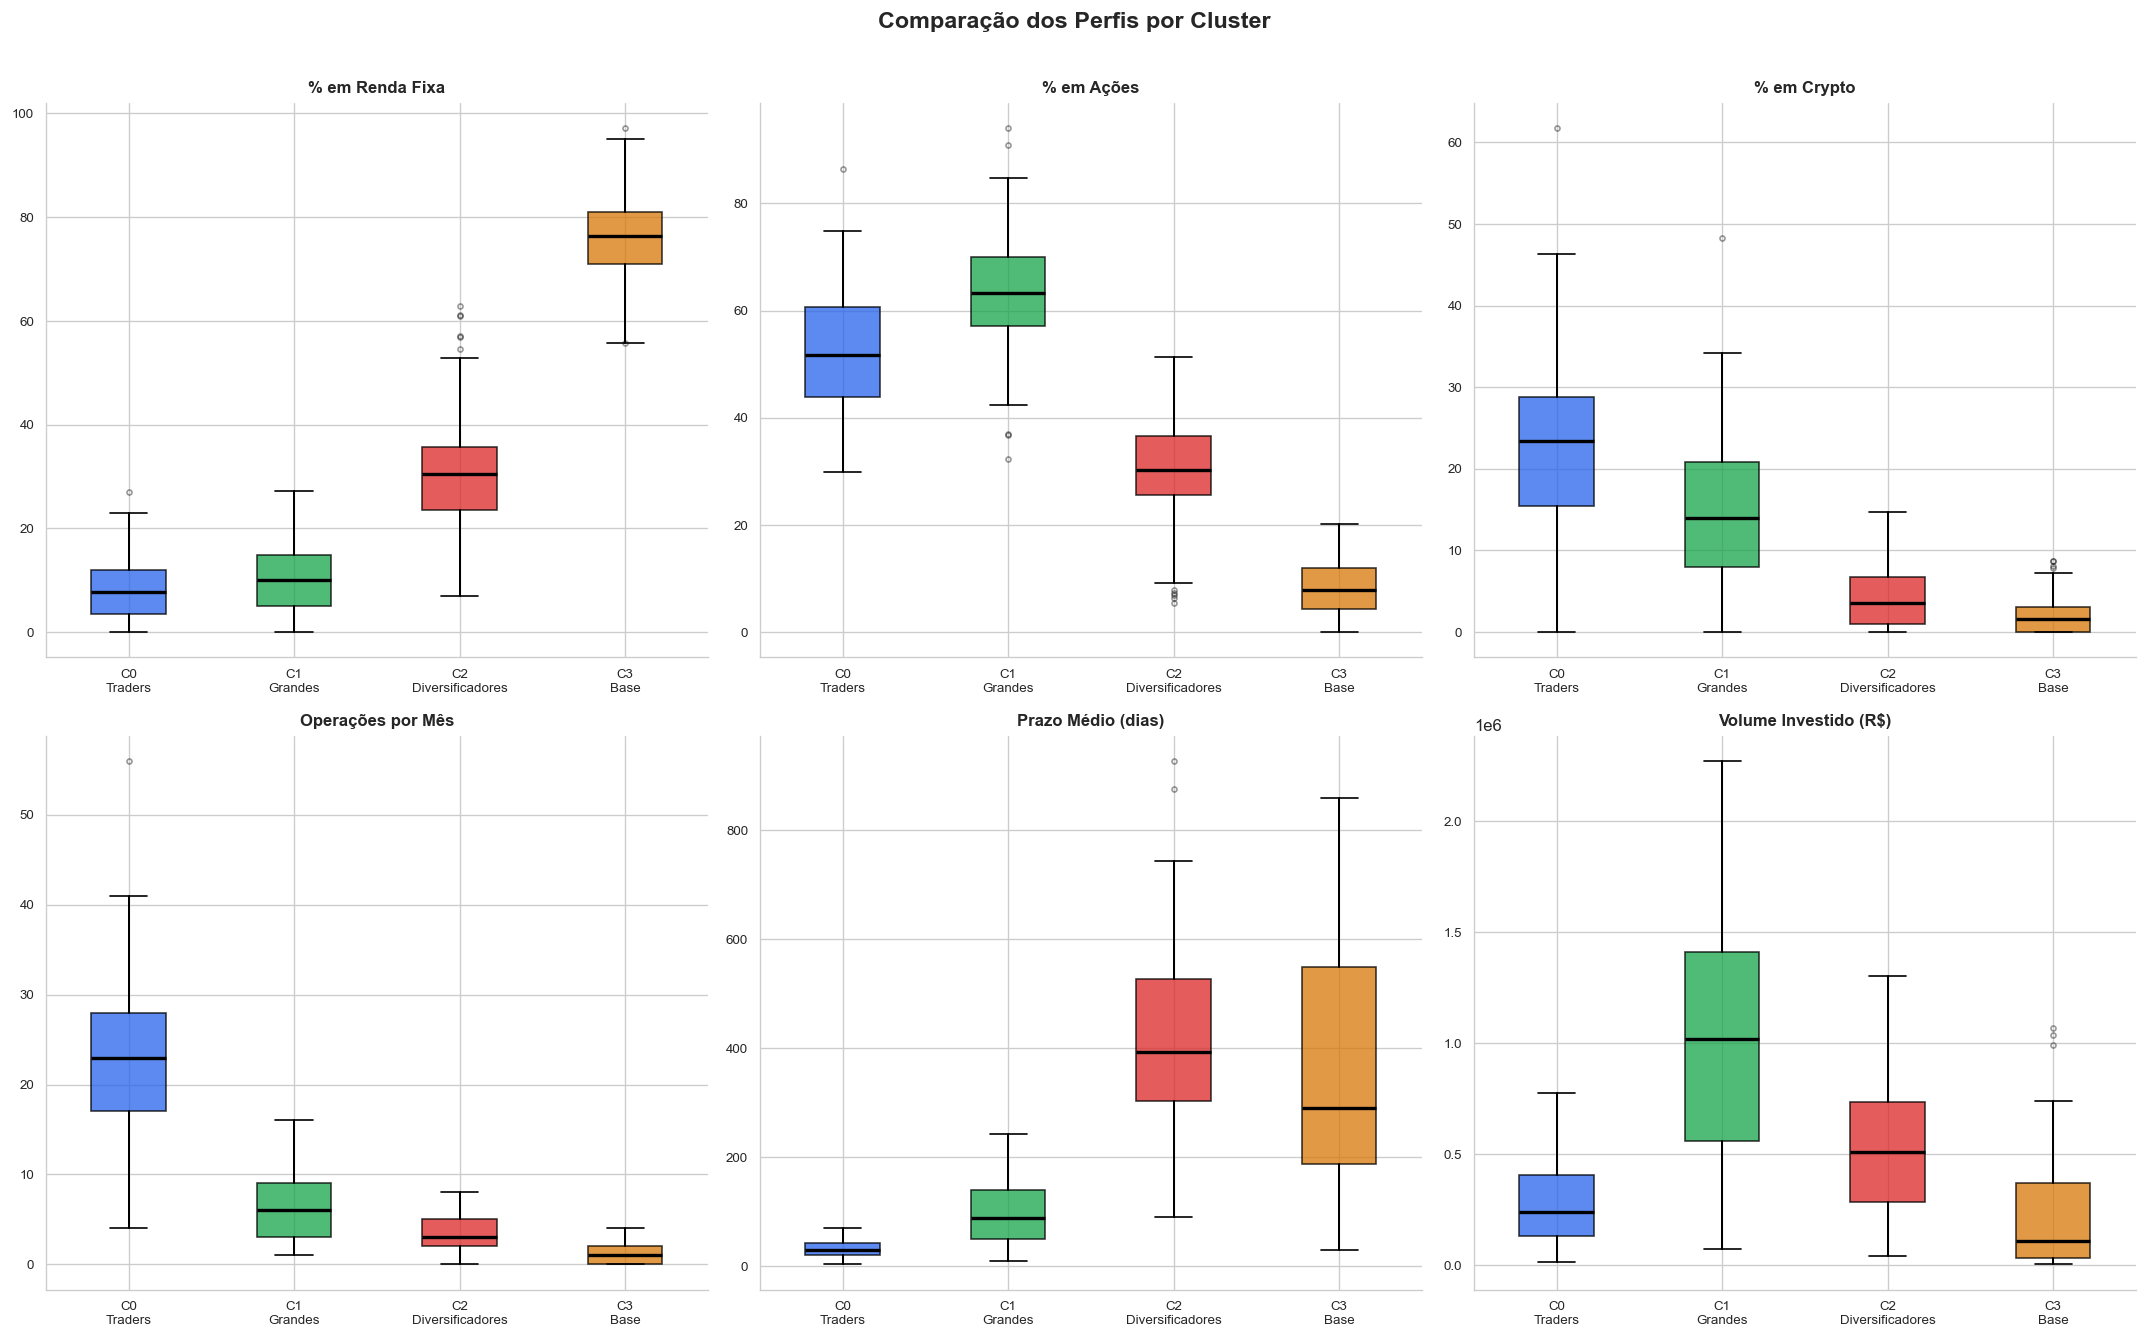

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

compare_vars = [
    ('perc_renda_fixa', '% em Renda Fixa'),
    ('perc_acoes', '% em Ações'),
    ('perc_crypto', '% em Crypto'),
    ('operacoes_por_mes', 'Operações por Mês'),
    ('prazo_medio_posicao_dias', 'Prazo Médio (dias)'),
    ('valor_total_investido_R$', 'Volume Investido (R$)')
]

for ax, (var, label) in zip(axes.flatten(), compare_vars):
    data = [df[df['cluster']==c][var].values for c in sorted(df['cluster'].unique())]
    cluster_labels = [f'C{c}\n{cluster_names[c].split()[0]}' for c in sorted(df['cluster'].unique())]
    
    bp = ax.boxplot(data, labels=cluster_labels, patch_artist=True,
                    medianprops={'color': 'black', 'linewidth': 2},
                    whiskerprops={'linewidth': 1.2},
                    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4})
    
    for patch, color in zip(bp['boxes'], PALETTE[:K_FINAL]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    
    ax.set_title(label, fontweight='bold', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=8)

plt.suptitle('Comparação dos Perfis por Cluster', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 7.6 Cluster vs. Perfil Autodeclarado — A Divergência

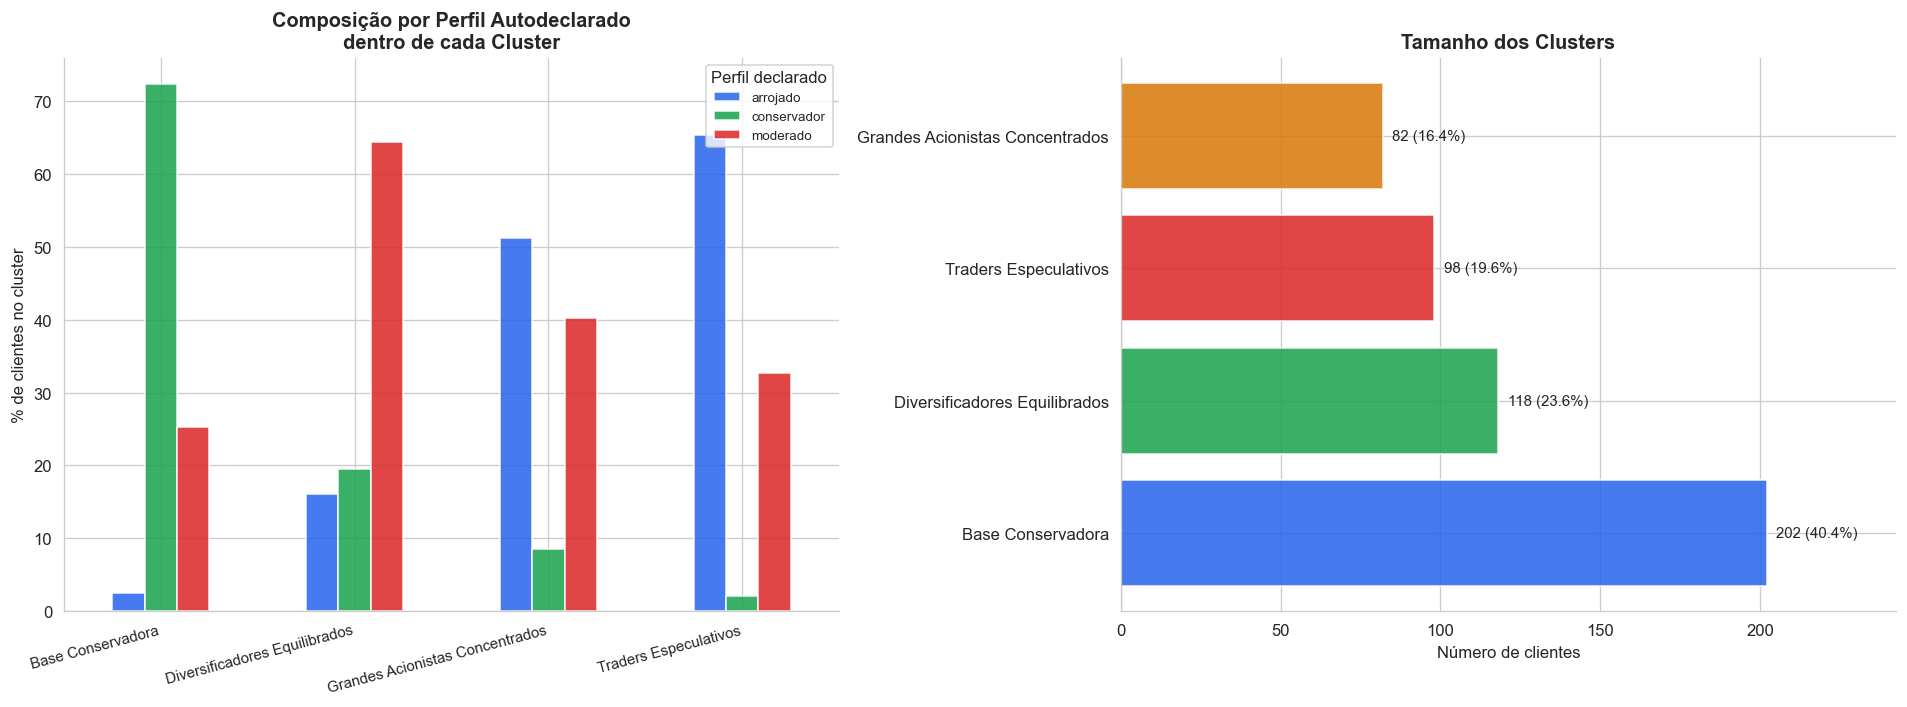

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribuição de perfil declarado por cluster
ax = axes[0]
cross = pd.crosstab(df['cluster_nome'], df['perfil_declarado_pelo_cliente'])
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

cross_pct.plot(kind='bar', ax=ax, color=['#2563EB', '#16A34A', '#DC2626'], 
               alpha=0.85, edgecolor='white')
ax.set_xlabel('')
ax.set_ylabel('% de clientes no cluster')
ax.set_title('Composição por Perfil Autodeclarado\ndentro de cada Cluster', fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right', fontsize=9)
ax.legend(title='Perfil declarado', fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Tamanho dos clusters
ax2 = axes[1]
sizes = df['cluster_nome'].value_counts()
bars = ax2.barh(sizes.index, sizes.values, color=PALETTE[:K_FINAL], alpha=0.85, edgecolor='white')
for bar, v in zip(bars, sizes.values):
    ax2.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2, 
             f'{v} ({100*v/len(df):.1f}%)', va='center', fontsize=9)
ax2.set_xlabel('Número de clientes')
ax2.set_title('Tamanho dos Clusters', fontweight='bold')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xlim(0, sizes.max() * 1.2)

plt.tight_layout()
plt.show()

---
## 8. Interpretação Final dos Perfis

Com base na análise quantitativa dos centroides, definimos quatro perfis comportamentais:

---

### Perfil 1 — Traders Especulativos (Cluster 0) — 98 clientes, 19,6% da base

**Quem são:** O grupo mais ativo e de maior risco. Concentram ~52% em ações e ~22% em crypto, com prazo médio de posição de apenas **30 dias** — os menores da base — e realizam em média **22 operações por mês**. São jovens (média 32 anos), diversificados em muitos ativos (12 em média) e têm volume investido intermediário (~R$266K).

**Sinal de alerta:** 32 desses clientes se autodeclaram "moderados" e 2 se declaram "conservadores", mas o comportamento é o mais arrojado da base. Há um desalinhamento sério entre percepção e realidade.

**O que a equipe deve fazer:**
- Oferecer análise de qualidade e ideias táticas — eles querem conteúdo, não conversa
- Conversar sobre gestão de risco, diversificação e custo de transação (emolumentos, IR)
- Monitorar concentração em crypto — se estiver crescendo, pode ser sinal de comportamento impulsivo
- Produtos: ações, BDRs, ETFs, derivativos, fundos multimercado

---

### Perfil 2 — Grandes Acionistas Concentrados (Cluster 1) — 82 clientes, 16,4% da base

**Quem são:** O grupo de maior patrimônio (volume médio investido de **R$1 milhão**). Têm 64% em ações, mas diferente dos Traders — operam com moderação (6x/mês) e mantêm posições por ~96 dias. A maior posição representa em média **67% da carteira** — são convictos, não ansiosos. Têm em média apenas 2,5 ativos na carteira. Idade média 48 anos.

**Sinal de alerta:** 33 se declaram "moderados" e 7 "conservadores", mas a carteira é claramente arrojada em ações. São clientes de alto valor com perfil mal categorizado.

**O que a equipe deve fazer:**
- Respeitar a estratégia deles — são investidores experientes e têm convicção
- Oferecer análise fundamentalista profunda, acesso a research exclusivo
- Discutir diversificação geográfica e proteção de patrimônio (hedge, exterior)
- São candidatos a produtos exclusivos e gestão personalizada
- Produtos: ações small/mid cap, fundos exclusivos, carteiras administradas, BDRs

---

### Perfil 3 — Diversificadores Equilibrados (Cluster 2) — 118 clientes, 23,6% da base

**Quem são:** O perfil mais sofisticado em termos de estratégia. Distribuem o patrimônio entre renda fixa (~31%), ações (~30%) e FIIs (~27%) de forma consciente. Mantêm posições por **409 dias** em média, têm 8 ativos distintos e operam ~3x/mês. Volume médio de ~R$523K. Idade média 43 anos.

**Destaque:** São os mais bem distribuídos em perfil declarado — 76 moderados, 23 conservadores, 19 arrojados — o que faz sentido, porque o comportamento deles é genuinamente equilibrado.

**O que a equipe deve fazer:**
- Valorizar a estratégia de diversificação — eles têm uma tese e a executam
- Oferecer revisão de carteira com foco em correlação de ativos e alocação tática
- Explorar internacionalização — exterior está em ~8%, há espaço para crescer
- Produtos: FIIs, fundos de crédito privado, Tesouro IPCA+, ações de dividendos, ETFs internacionais

---

### Perfil 4 — Base Conservadora (Cluster 3) — 202 clientes, 40,4% da base

**Quem são:** O maior grupo — 40% da base. Têm **76% em renda fixa**, operam apenas **1,2x/mês** e mantêm posições por 362 dias. Volume médio de ~R$219K — o menor entre os clusters. Concentração alta (~60% em um único ativo). Apenas 2,9 ativos distintos.

**Sinal de alerta:** 146 se declaram conservadores (alinhado), mas 51 se declaram moderados sem ter nem uma posição relevante em renda variável. Podem estar subestimando o potencial de retorno que poderiam ter.

**O que a equipe deve fazer:**
- Para quem quer ser conservador de verdade: foco em rentabilidade dentro do universo de renda fixa (LCI, LCA, CDB de bancos menores, Tesouro IPCA+)
- Para quem se diz moderado mas tem 76% em RF: abrir conversa sobre FIIs ou fundos de crédito como primeiro passo
- Cadência de contato menor, mas constante — esses clientes valorizam estabilidade
- São o grupo com maior potencial de up-sell se abordados da forma certa (sem forçar risco que não querem)


---
## 9. Resposta ao E-mail do Rafael

---

**Para:** Rafael Mendes, Head de Relacionamento  
**Assunto:** RE: Segmentação comportamental — resultados da análise

---

Rafael,

Concluí a análise. A intuição que você trouxe estava certa — e os dados confirmam com clareza.

**Sua hipótese estava correta.** O perfil autodeclarado não reflete o comportamento real na maioria dos casos. Na base de 500 clientes, encontrei clientes que se declaram "conservadores" mas têm 52% da carteira em ações e crypto, e clientes que se dizem "moderados" mas mantêm 76% em renda fixa e mal fazem uma operação por mês. A etiqueta que o cliente coloca em si mesmo é um ponto de partida fraco para guiar o atendimento.

Rodei uma análise de agrupamento nos dados comportamentais — como os clientes alocam de fato, com que frequência operam, por quanto tempo ficam com cada posição — e encontrei **quatro perfis distintos**. Veja o que cada um representa:

---

**1. Traders Especulativos — 98 clientes (19,6% da base)**

Clientes jovens (média 32 anos) com carteiras dominadas por ações (~52%) e crypto (~22%). Operam com frequência alta — em média 22 vezes por mês — e raramente ficam com uma posição por mais de 30 dias. São os mais ativos e os que tomam mais risco, mas boa parte deles se autodeclara "moderado". Precisam de um assessor que chegue com análise e oportunidades, não com cautela.

*Sugestão de abordagem:* contato frequente, conteúdo analítico, conversa sobre gestão de risco e custo de transação. Produtos: ações, ETFs, derivativos.

---

**2. Grandes Acionistas Concentrados — 82 clientes (16,4% da base)**

O grupo de maior patrimônio investido — média de R$1 milhão por cliente. Investem pesado em ações (~64%) mas não são traders: operam cerca de 6 vezes por mês e mantêm posições por ~96 dias. Têm poucos ativos na carteira (2,5 em média) e alta concentração — o maior ativo representa 67% do portfólio. São investidores experientes com convicção. Muitos se declaram "moderados", mas são os nossos clientes mais arrojados em patrimônio.

*Sugestão de abordagem:* respeitar a estratégia deles. Trazer research exclusivo, análise fundamentalista, discussão sobre internacionalização e proteção de patrimônio. Produtos: fundos exclusivos, carteiras administradas, BDRs.

---

**3. Diversificadores Equilibrados — 118 clientes (23,6% da base)**

O grupo mais sofisticado em termos de estratégia. Distribuem o patrimônio conscientemente entre renda fixa (~31%), ações (~30%) e FIIs (~27%), com prazo médio de 409 dias. São pacientes, diversificados (8 ativos em média) e têm volume médio de R$523K. É o grupo onde o perfil autodeclarado tem mais alinhamento com o comportamento real — porque a postura deles é genuinamente equilibrada.

*Sugestão de abordagem:* revisão de carteira com foco em correlação de ativos. Explorar aumento da exposição ao exterior (hoje em ~8%). Produtos: FIIs, fundos de crédito, ETFs internacionais, Tesouro IPCA+.

---

**4. Base Conservadora — 202 clientes (40,4% da base)**

O maior grupo. São clientes com 76% em renda fixa, que operam cerca de uma vez por mês e ficam com as posições por quase um ano. Patrimônio investido menor (R$219K em média). A maioria se declara conservadora — mas 51 clientes que se dizem "moderados" têm um comportamento que é, na prática, conservador. Podem estar subestimando o quanto poderiam rentabilizar sem sair da zona de conforto.

*Sugestão de abordagem:* para os genuinamente conservadores — foco em rentabilidade dentro de renda fixa (LCI/LCA, CDB de bancos menores). Para os que se dizem moderados — abrir conversa sobre FIIs ou fundos de crédito como primeiro passo. Contato menos frequente, mas com consistência.

---

### O que sugiro como próximo passo

1. Compartilhar esses quatro perfis com a equipe de relacionamento e pedir que eles reconheçam clientes — a validação qualitativa é importante antes de qualquer mudança operacional
2. Criar playbooks específicos por perfil: tom de comunicação, cadência de contato, produtos prioritários
3. Acompanhar por 6 meses se o atendimento personalizado melhora os indicadores de satisfação e volume por grupo

Fico à disposição para detalhar qualquer perfil ou rodar análises complementares.

Abs,  
Guilherme

---
## 10. Reflexões Metodológicas e Limitações

### O que funcionou bem
- A normalização antes do K-Means foi essencial — sem ela, `patrimonio_declarado_R$` dominaria todo o espaço de distâncias
- Usar múltiplos critérios de validação (Elbow + Silhouette + Davies-Bouldin) tornou a escolha de K mais defensável do que um único critério
- Excluir `perfil_declarado_pelo_cliente` dos inputs foi correto — usá-lo seria contaminar a análise com exatamente aquilo que queríamos questionar

### Limitações e próximas iterações
1. **K-Means assume clusters esféricos** — um próximo passo seria testar DBSCAN (bom para clusters de forma livre) ou Gaussian Mixture Models (que lidam melhor com clusters sobrepostos)
2. **Não incluímos dados temporais** — comportamento evolui. Um cliente que era iniciante há 3 anos pode estar em transição para diversificador. Seria valioso analisar a trajetória ao longo do tempo.
3. **Variáveis ausentes** — rentabilidade histórica, origem de patrimônio (herança vs. acumulação), eventos de vida (casamento, aposentadoria) provavelmente aumentariam o poder preditivo
4. **Estabilidade dos clusters** — rodar com diferentes `random_state` e verificar se os mesmos clientes caem no mesmo cluster é um teste de robustez que deve ser feito antes de colocar isso em produção
5. **Avaliação de negócio** — a validação mais importante não é técnica, mas qualitativa: os assessores reconhecem esses perfis no dia a dia?